In [1]:
from lpspline import l
from lpspline import Log
import polars as pl
import numpy as np


N = 1000
X = pl.DataFrame({
    'x': np.linspace(1.,10, N)
})
y = pl.Series(np.log(X['x']) + np.random.randn(N)*0.1)


In [2]:
# y = log(x): the wrapper is the function applied to the splines
model = Log(
    +l(term='x')
)
model.fit(X, y)

Log(LpRegressor(splines=[Linear(term='x', bias=True, by=None)]))

Text(0.5, 1.0, 'Link regression')

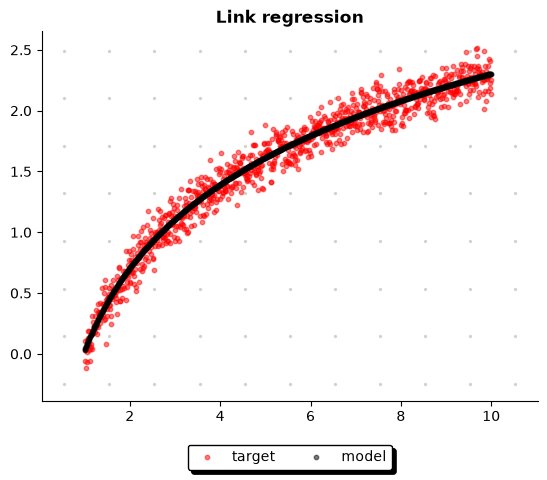

In [3]:
import matplotlib.pyplot as plt
import pimpmyplot as pmp

plt.scatter(X['x'], y, color='r', alpha=.5, s=10, label='target')
plt.scatter(X['x'], model.predict(X), color='k', alpha=.5, s=10, label='model')
pmp.legend()
pmp.remove_axis('top', 'right')
pmp.bullet_grid()
plt.title('Link regression', fontweight='bold')
